In [2]:
# Hadijah Tohepaly - 202431078
# 1. Import Library
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# 2. Membaca Dataset
df = pd.read_csv("hasil_scraping.csv")

# Menampilkan data
df.head()


,sku,nama_produk,maker,kategori,pack,harga,harga_sebelumnya,stock,lead_time,rating,reviews
0,NWT-10000,"Cast Iron Mug Set, Oat — Small",Fieldhouse,Tabletop,1,186.94,NaN,In stock,2 weeks,4.8,209
1,NWT-10001,"Wool Skillet, Large — Medium",Aoyama Works,Kitchen,2,137.45,NaN,In stock,2–3 days,4.5,261
2,NWT-10002,"Walnut Side Table, Large — Large",Tessa Ruiz Studio,Furniture,2,88.68,NaN,Low stock,ships today,3.2,128
3,NWT-10003,"Wool Bowl, Clay — Extra large",Aoyama Works,Tabletop,6,95.54,NaN,Low stock,4–6 weeks,4.8,165
4,NWT-10004,"Slate Vase, Ink — Natural",Brock Forge,Decor,2,386.92,NaN,Low stock,1 week,4.0,280


In [3]:
# Hadijah Tohepaly_202431078
# 3. Menghapus Data Kosong
df = df.dropna(subset=["harga_sebelumnya", "harga"])

# 4. Menentukan Fitur dan Target
X = df[["harga_sebelumnya"]]
y = df["harga"]

# Menampilkan jumlah data
print("Jumlah data:", len(df))


Jumlah data: 75


In [4]:
# Hadijah Tohepaly_202431078
# 5. Membagi Data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

print("Data latih:", len(X_train))
print("Data uji:", len(X_test))


Data latih: 60
Data uji: 15


In [5]:
# Hadijah Tohepaly_202431078
# 6. Membuat Model
model = LinearRegression()

# 7. Melatih Model
model.fit(X_train, y_train)


LinearRegression()

In [6]:
# Hadijah Tohepaly_202431078
# 8. Prediksi Data Uji
y_pred = model.predict(X_test)

# Menampilkan hasil prediksi
hasil = pd.DataFrame({
    "Harga Sebelumnya": X_test["harga_sebelumnya"],
    "Harga Aktual": y_test,
    "Harga Prediksi": y_pred
})

hasil.head()

,Harga Sebelumnya,Harga Aktual,Harga Prediksi
137,1898.86,1769.25,1470.104155
150,481.30,387.29,387.662312
54,358.47,291.10,293.869928
199,230.81,187.35,196.389380
70,233.04,202.65,198.092197


In [7]:
# Hadijah Tohepaly_202431078
# 9. Evaluasi Model

print("Koefisien:", model.coef_[0])
print("Intercept:", model.intercept_)

mse = mean_squared_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("MSE:", mse)
print("R2 Score:", r2)


Koefisien: 0.7635950811808508
Intercept: 20.143999094066658
MSE: 7052.466582808891
R2 Score: 0.959149848722133


In [8]:
# Hadijah Tohepaly_202431078
# 10. Persamaan Regresi

a = model.intercept_
b = model.coef_[0]

print(f"Persamaan Regresi: Y = {a:.2f} + {b:.4f}X")


Persamaan Regresi: Y = 20.14 + 0.7636X


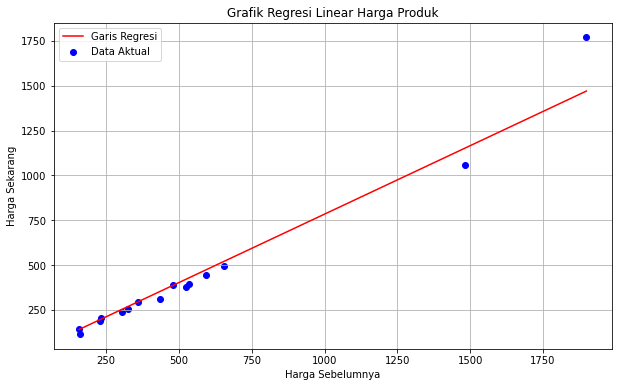

In [9]:
# Hadijah Tohepaly_202431078
# 11. Visualisasi Regresi Linear

plt.figure(figsize=(10, 6))

# Scatter Plot Data Aktual
plt.scatter(X_test["harga_sebelumnya"], y_test,
            color="blue", label="Data Aktual")

# Garis Regresi
x_garis = np.linspace(X_test["harga_sebelumnya"].min(),
                      X_test["harga_sebelumnya"].max(), 100)

y_garis = model.predict(pd.DataFrame({
    "harga_sebelumnya": x_garis
}))

plt.plot(x_garis, y_garis,
         color="red", label="Garis Regresi")

plt.title("Grafik Regresi Linear Harga Produk")
plt.xlabel("Harga Sebelumnya")
plt.ylabel("Harga Sekarang")
plt.legend()
plt.grid(True)

plt.show()
